Locker selezionati: [102, 101, 107, 105, 106, 112, 104, 108]
Copertura locker selezionati:
Locker 102: copre 16 clienti
Locker 101: copre 15 clienti
Locker 107: copre 14 clienti
Locker 105: copre 13 clienti
Locker 106: copre 12 clienti
Locker 112: copre 12 clienti
Locker 104: copre 10 clienti
Locker 108: copre 9 clienti

Assegnamento greedy completato:
Clienti totali: 100
Clienti diretti: 21
Clienti assegnati ai locker: 79
Locker attivi: [101, 102, 104, 105, 106, 107, 108, 112]
Locker 101: 11 clienti assegnati
Locker 102: 9 clienti assegnati
Locker 104: 10 clienti assegnati
Locker 105: 12 clienti assegnati
Locker 106: 8 clienti assegnati
Locker 107: 13 clienti assegnati
Locker 108: 9 clienti assegnati
Locker 112: 7 clienti assegnati

REPORT EURISTICA - GREEDY PURO
Valore funzione obiettivo greedy: 2127.77
Costo routing: 1938.51
Costo locker fisso: 189.26
Tempo computazionale: 0.0018 secondi
Veicoli usati: 8

STATISTICHE CONSEGNE
Clienti serviti direttamente: 21
Clienti serviti tramite 

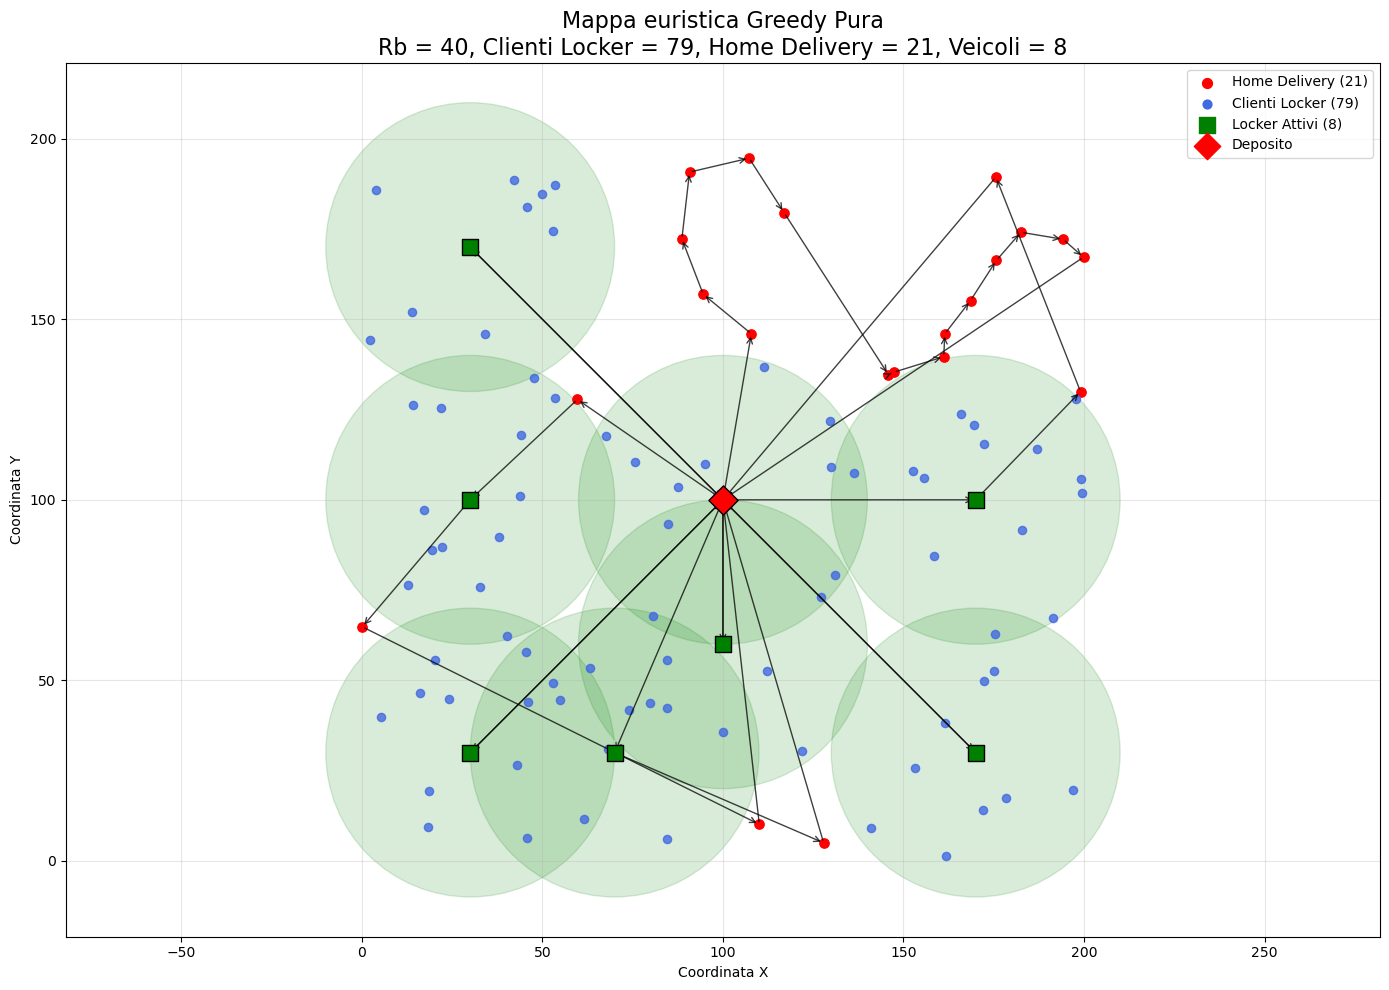

In [3]:
import gurobipy as gp
from gurobipy import GRB
import math  #importa funzioni matematiche o meglio la libreria matematica standard di python
import random  #serve per generare numeri casuali relativi ai parametri dell'istanza grande (posizioni casuali\domande variabili)
import time #consente di misurare il tempo di esecuzione dell'euristica greedy pura 

# STEP 1 - GENERAZIONE ISTANZA
#definisco l'istanza in cui opera l'euristica greedy pura 
random.seed(42) #garantisce riproducibilità 
 
n_clienti = 100 #numero dei clienti
n_lockers = 12 #numero dei lockers disponibili
 
customers = list(range(1, n_clienti + 1))  #definisco l'insieme dei nodi clienti ,quest'ultimi sono identificati con interi consecutivi
lockers = list(range(n_clienti + 1, n_clienti + n_lockers + 1)) #definisco l'insieme dei nodi lockers anch'essi identificati con interi consecutivi
nodes = [0] + customers + lockers  #creo l'insieme completo dei nodi costituito dal nodo deposito , dai nodi clienti e dai nodi lockers
 
# PARAMETRI 

R_b = 40        #raggio di copertura,un cliente può usare un locker solo se dista <= 40
Q = 15         #capacità limitata del veicolo , ora può trasportare 15 pacchi
K = 10          #numero massimo di veicoli (saturazione estrema) solo 10 veicoli per 100 clienti
v_b = 15       #capacità limitata di ogni locker, ora può contenere 15 pacchi
alpha1 = 1.0     #coefficiente di bilanciamento della FO ,rappresenta il peso relativo al costo del trasporto\routing
alpha2 = 0.1    #coefficiente di bilanciamento della FO , rappresenta il peso relativo al costo di accesso dei clienti al locker
 
# DEFINISCO LE COORDINATE DEL DEPOSITO , DEI CLIENTI E DEI LOCKERS
coords = {}
coords[0] = (100, 100)  #coordinate del deposito centrale
 

#dispongo i clienti in modo casuale nella mappa 200x200
for i in customers:
    coords[i] = (
        random.uniform(0, 200),
        random.uniform(0, 200)
    )
 
#i lockers occupano invece delle posizioni strategiche, tale disposizione strategica fornisce all'euristica greedy pura una 
#struttura geometrica stabile su cui costruire cluster e decomposizioni del problema

locker_positions = [
    (30, 30), (70, 30), (130, 30), (170, 30),
    (30, 100), (100, 100), (170, 100),
    (30, 170), (70, 170), (130, 170), (170, 170),
    (100, 60)
]
for b, pos in zip(lockers, locker_positions):
    coords[b] = pos #accoppia l'ID del locker(101-112) con la sua coordinata(x,y)
 
# MATRICE DELLE DISTANZE
dist = {
    (i, j): math.sqrt(
        (coords[i][0] - coords[j][0])**2 +
        (coords[i][1] - coords[j][1])**2
    )
    for i in nodes for j in nodes
}
#la matrice delle distanze costituisce la base geometrica dell'euristica greedy pura : consente di identificare cluster naturali, ridurre lo spazio di ricerca 
#e costruire sottoproblemi localizzati che il solver può risolvere esattamente con tempi computazionali ridotti

# STEP 2 - SELEZIONE DEI LOCKER PIÙ PROMETTENTI
#l'euristica greedy pura riduce il problema selezionando solo 8 locker, scelti in base alla copertura (numero di clienti servibili entro il raggio R_b)
copertura_locker = {}
 
for b in lockers:
    clienti_coperti = [i for i in customers if dist[i, b] <= R_b] #si contano i clienti entro il raggio R_b e si memorizza il numero di clienti coperti
    copertura_locker[b] = len(clienti_coperti) #indicatore di qualità del locker b-esimo
 
#ordiniamo i lockers per copertura decrescente (cioè da quello che copre più clienti a quello che ne copre meno)
locker_ordinati = sorted(
    copertura_locker.items(),
    key=lambda x: x[1],
    reverse=True
)
 
n_locker_da_aprire = 8 #riduzione del problema,scelgo di aprire solo 8 lockers
distanza_minima_tra_locker = 30 #devono essere distanti almeno 30 unità ,introduco dunque un criterio di diversità spaziale
 
lockers_selezionati = []
 
for b, copertura in locker_ordinati:
    if len(lockers_selezionati) >= n_locker_da_aprire:
        break
 
    troppo_vicino = any(
        dist[b, scelto] < distanza_minima_tra_locker
        for scelto in lockers_selezionati
    )
 
    if not troppo_vicino:
        lockers_selezionati.append(b)
#per ogni locker in ordine di copertura,se ho già selezionato 8 lockers mi fermo, poi controllo se il locker è già troppo vicino a quelli già scelti e se 
#non è troppo vicino lo seleziono

print("Locker selezionati:", lockers_selezionati)
print("Copertura locker selezionati:")
for b in lockers_selezionati:
    print(f"Locker {b}: copre {copertura_locker[b]} clienti")
#la parte finale di questa fase serve per verificare quali locker sono stati scelti ,quanta copertura garantiscono e se la selezione è equilibrata

# STEP 3 - ASSEGNAMENTO GREEDY CLIENTE-LOCKER
 
assignment = {i: None for i in customers} #per ogni cliente, indica il locker assegnato (None se il cliente è servito dal veicolo a domicilio)
locker_load = {b: 0 for b in lockers_selezionati}   #carico di ciascun locker selezionato
locker_load[b] < v_b  #il carico di ciascun locker selezionato deve rispettare il limite di capacità del locker stesso 
 
ordered_customers = sorted(
    customers,
    key=lambda i: dist[0, i],
    reverse=True  
)
#clienti ordinati per distanza dal deposito, dal più lontano al più vicino
#si gestiscono prima i clienti più lontani dal deposito perchè sono quelli che conviene spostare sui locker per ridurre la distanza del routing  
for i in ordered_customers:
 
    feasible_lockers = [
        b for b in lockers_selezionati
        if dist[i, b] <= R_b and locker_load[b] < v_b
    ]  #per feasible lockers intendo lockers selezionati che sono entro il raggio R_b del cliente i e che non hanno saturato la capacità v_b
 
    if feasible_lockers:
        best_b = min(feasible_lockers, key=lambda b: dist[i, b])
        assignment[i] = best_b#tra i locker possibili scelgo il piu vicino
        locker_load[best_b] += 1 #la capacità occupata aumenta di 1
    else:
        assignment[i] = None 
#se esistono lockers fattibili , si sceglie quello più vicino (min sulla distanza) ,si assegna il cliente a quel locker e si aggiorna il 
#carico del locker ; se non esistono allora il cliente viene servito dal veicolo 
direct_customers = [i for i in customers if assignment[i] is None] #clienti serviti dal veicolo
 
active_lockers = sorted(
    set(b for b in assignment.values() if b is not None)
) #solo i lockers che hanno almeno un cliente assegnato
 
visit_nodes = [0] + direct_customers + active_lockers  #insieme dei nodi che il veicolo deve considerare nel routing ,deposito ,clienti diretti e locker attivi
 
print("\nAssegnamento greedy completato:")
print(f"Clienti totali: {len(customers)}")
print(f"Clienti diretti: {len(direct_customers)}")
print(f"Clienti assegnati ai locker: {len(customers) - len(direct_customers)}")
print(f"Locker attivi: {active_lockers}")
#stampa tutte quelle che sono le statistiche chiave 
for b in active_lockers:
    print(f"Locker {b}: {locker_load[b]} clienti assegnati")
 
# STEP 4 - ROUTING GREEDY PURO
start_time = time.time() #serve a misurare il tempo computazionale dell'euristica, serve inoltre per confrontare la velocità della greedy 
#pura con la matheuristic e con il modello esatto
 
# DOMANDA ASSOCIATA AD OGNI NODO DA VISITARE 

demand = {} #si crea un dizionario che conterrà la domanda associata a ciascun nodo da visitare
 
for i in direct_customers:
    demand[i] = 1 #ogni cliente diretto richiede una consegna singola, quindi la sua domanda è pari a uno
 
for b in active_lockers:
    demand[b] = locker_load[b]
                               
#gni locker attivo ha una domanda pari al numero di clienti assegnati,il locker viene trattato come un nodo aggregato che richiede più 
#capacità del veicolo                                
unvisited = set(direct_customers + active_lockers) #si costruisce l’insieme dei nodi che devono essere visitati: clienti diretti e locker attivi che è 
#l’unico insieme su cui lavora la greedy pura
 
routes = [] #conterrà tutte le rotte costruite
routing_cost = 0 #accumulerà la distanza totale percorsa dai veicoli
 
while unvisited and len(routes) < K: #questo ciclo continua (si costruiscono nuove rotte) finchè ci sono nodi da servire o fin quando si supera il numero massimo di veicoli K
     
#INIZIALIZZAZIONE DELLA ROTTA 
    route = [0]      #qui inizializziamo una nuova rotta , essa parte dal deposito
    current_node = 0 #il nodo corrente è il deposito
    remaining_capacity = Q #la capacità residua è inizialmente pari alla capacità totale del veicolo
    route_load = 0 #il carico consegnato è zero
 
    while True:
 
        feasible_nodes = [
            node for node in unvisited
            if demand[node] <= remaining_capacity
        ] 
#si selezionano solo i nodi la cui domanda è compatibile con la capacità residua del veicolo ,se un nodo richiede più capacità di quella disponibile, 
#ovviamente non può essere servito
 
        if not feasible_nodes:
            break
#il veicolo non può servire altri nodi e dovrà tornare al deposito


#AGGIORNAMENTO DELLA ROTTA - scelta greedy del prossimo nodo
        next_node = min(
            feasible_nodes,
            key=lambda node: dist[current_node, node]
        ) #tra i nodi compatibili, viene scelto quello più vicino al nodo corrente, questa è la mossa greedy che consiste nella minimizzazione locale della distanza
 
        route.append(next_node)
        routing_cost += dist[current_node, next_node] #il nodo viene aggiunto alla rotta ed il costo aumenta della distanza percorsa
        
 
        remaining_capacity -= demand[next_node] #La capacità residua diminuisce della domanda del nodo servito
        route_load += demand[next_node] #il carico consegnato aumenta
 
        unvisited.remove(next_node) #il nodo viene rimosso dai nodi da visitare
        current_node = next_node #ora la posizione corrente diventa il nodo appena servito
 
#quando il veicolo non può servire altri nodi, torna al deposito e si aggiunge il costo del ritorno
    route.append(0)
    routing_cost += dist[current_node, 0]


    routes.append({
        "route": route,
        "load": route
        }) 
#la rotta viene salvata ed il dizionario contiene la sequenza dei nodi visitati ed il carico servito
 
heur_time = time.time() - start_time #si calcola il tempo totale impiegato dalla greedy pura, che è sempre molto basso
 
if unvisited:
    print("ATTENZIONE: non tutti i nodi sono stati serviti.")
    print("Nodi non serviti:", unvisited)
#se restano nodi non serviti, significa che la capacità totale dei veicoli non è sufficiente
#la greedy pura non ottimizza globalmente, quindi può fallire nel coprire tutti i nodi

# STEP 5 - REPORT GREEDY PURO
#qui viene calcolato il costo associato ai clienti assegnati ai locker
locker_penalty_fixed = sum(
    alpha2 * dist[i, assignment[i]]  #per ogni cliente assegnato, si moltiplica la distanza dal locker per il peso alfa2
    for i in customers
    if assignment[i] is not None
) #si tratta di un costo completamente determinato dalla fase greedy quindi non viene ottimizzato
 
obj_greedy = alpha1 * routing_cost + locker_penalty_fixed #la FO combina due componenti ossia il costo di routing ed il costo fisso dei locker
 
print("\n" + "=" * 60)
print("REPORT EURISTICA - GREEDY PURO") #inizia la stampa dei risultati dell'euristica
print("=" * 60)
#stampiamo i valori fondamentali
print(f"Valore funzione obiettivo greedy: {obj_greedy:.2f}")
print(f"Costo routing: {routing_cost:.2f}")
print(f"Costo locker fisso: {locker_penalty_fixed:.2f}")
print(f"Tempo computazionale: {heur_time:.4f} secondi")
print(f"Veicoli usati: {len(routes)}")
 
print("\nSTATISTICHE CONSEGNE") #qui si vede come la greedy ha distribuito i clienti
print(f"Clienti serviti direttamente: {len(direct_customers)}")
print(f"Clienti serviti tramite locker: {len(customers) - len(direct_customers)}")
print(f"Locker attivi: {len(active_lockers)}")
 
print("\nPERCORSI GREEDY")
for idx, r in enumerate(routes, start=1):
    print(f"Veicolo {idx} | Carico: {r['load']} | Percorso: {r['route']}") #per ogni veicolo viene mostrato : il carico servito e la sequenza di nodi visitati

# STEP 6 - VISUALIZZAZIONE GRAFICA EURISTICA GREEDY PURA

import matplotlib.pyplot as plt #importa la libreria necessaria per creare la figura grafica della soluzione greedy
 
plt.figure(figsize=(14, 10))  #crea una nuova figura grande 14×10, così da avere spazio per visualizzare tutti i nodi e le rotte

# CLIENTI SERVITI A DOMICILIO
#per ogni cliente diretto viene disegnato un punto rosso nella sua posizione geografica , sono le consegne a domicilio
for i in direct_customers:
    plt.scatter(
        coords[i][0],
        coords[i][1],
        color="red",
        s=45,
        zorder=3
    )
 

# CLIENTI ASSEGNATI AI LOCKER
#costruisco la lista dei clienti assegnati ai lockers
locker_customers = [
    i for i in customers
    if assignment[i] is not None
]
 
for i in locker_customers:
    plt.scatter(
        coords[i][0],
        coords[i][1],
        color="royalblue",
        s=35,
        alpha=0.8,
        zorder=3
    ) #ogni cliente assegnato ad un locker viene contrassegnato con un punto blu
 

# LOCKER ATTIVI + RAGGIO DI COPERTURA
#ogni locker attivo viene rappresentato come un quadrato verde con bordo nero
for b in active_lockers:
    plt.scatter(
        coords[b][0],
        coords[b][1],
        color="green",
        marker="s",
        s=140,
        edgecolors="black",
        zorder=5
    )
 
    circle = plt.Circle(
        coords[b],
        R_b,
        color="green",
        alpha=0.15
    )
 
    plt.gca().add_patch(circle) #attorno al locker viene disegnato un cerchio che rappresenta il suo raggio di copertura R_b

# DEPOSITO
#il deposito viene disegnato come un simbolo rosso più grande e ben visibil 
plt.scatter(
    coords[0][0],
    coords[0][1],
    color="red",
    marker="D",
    s=220,
    edgecolors="black",
    zorder=6
) 
 

# ARCHI ATTIVI DEL ROUTING GREEDY
 
for r in routes:
    route = r["route"] #si scorre ogni rotta costruita dalla greedy pura
 
    for k in range(len(route) - 1):
        i = route[k]
        j = route[k + 1] #si considerano le coppie di nodi consecutivi nella rotta
 
        plt.annotate(
            "",
            xy=coords[j],
            xytext=coords[i],
            arrowprops=dict(
                arrowstyle="->",
                color="black",
                lw=1,
                alpha=0.75
            )
        )
#per ogni coppia di nodi viene disegnata una freccia che rappresenta il movimento del veicolo da i a j , questo visualizza il percorso 
#effettivo costruito dalla greedy pura

# LEGENDA

plt.scatter(
    [],
    [],
    color="red",
    s=50,
    label=f"Home Delivery ({len(direct_customers)})"
) #i punti rossi sono rappresentativi della home delivery
 
plt.scatter(
    [],
    [],
    color="royalblue",
    s=40,
    label=f"Clienti Locker ({len(locker_customers)})"
) #i punti blu sono rappresentativi dei clienti assegnati al locker
 
plt.scatter(
    [],
    [],
    color="green",
    marker="s",
    s=120,
    label=f"Locker Attivi ({len(active_lockers)})"
) #i quadrati verdi sono rappresentativi dei lockers attivi , ne mostra quanti sono stati effettivamente utilizzati
 
plt.scatter(
    [],
    [],
    color="red",
    marker="D",
    s=180,
    label="Deposito"
) #il simbolo rosso a forma di diamante7rombo è rappresentativo del deposito
 
# TITOLO E FORMATTAZIONE

 
plt.title(
    f"Mappa euristica Greedy Pura\n"
    f"Rb = {R_b}, Clienti Locker = {len(locker_customers)}, "
    f"Home Delivery = {len(direct_customers)}, Veicoli = {len(routes)}",
    fontsize=16 #serve a rendere il titolo più visibile
)
 
plt.xlabel("Coordinata X")
plt.ylabel("Coordinata Y")
plt.grid(alpha=0.3) #attiva una griglia sul grafico per visualizzare meglio le coordinate e dunque le posizioni dei nodi
plt.legend(loc="upper right") #mostra la legenda costruita in precedenza e la posiziona nell’angolo in alto a destra della figura
plt.axis("equal")
plt.tight_layout() #ottimizza la disposizione degli elementi grafici (titolo, legenda, assi) per evitare sovrapposizioni
plt.show() #mostra la figura completa con tutti gli elementi
 
